# 14 時系列の反復性と1年一括予測のラグ制約

店舗や商品カテゴリごとの日次売上について、曜日・週単位・前年付近の反復性を調べる。後半では2023年末や2024年末を予測基準日とした場合、**予測対象日のラグが基準日以前か**を日付で判定する。

履歴の相関は将来の予測精度を保証しない。短いラグの過去相関が高くても、翌年1年を基準日にまとめて予測する場合、将来期間の実績は使えない。予測を再帰的に利用する場合も、それが実績ではなく予測であることを明示し、誤差伝播を評価する。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'input').is_dir(): ROOT=ROOT.parent
assert (ROOT/'input').is_dir()
INPUT=ROOT/'input';sns.set_theme(style='whitegrid');pd.options.display.float_format='{:,.4f}'.format
train=pd.read_csv(INPUT/'train.csv',parse_dates=['date'])
menus=pd.read_csv(INPUT/'menus.csv')[['item_id','category','menu_type']]
train=train.merge(menus,on='item_id',validate='many_to_one')
daily=train.groupby(['date','store_id'],as_index=False).sales_amount.sum()
store_category=train.groupby(['date','store_id','category'],as_index=False).sales_amount.sum()
assert not daily.duplicated(['date','store_id']).any()
assert daily.date.nunique()==1096
print('日×店舗:',len(daily),'日×店舗×カテゴリ:',len(store_category))

日×店舗: 10960 日×店舗×カテゴリ: 65760


## 店舗日次売上のラグと相関
同一店舗の売上について、対象日とラグ日の両方が観測済みである履歴期間を調べる。対象年全体の相関は、年内の水準変化や季節を含む。ここでは将来予測を作らず、**履歴の記述統計**として示す。

lag_days,7,28,364,728
store_id,,,,
S001,0.6603,0.4959,0.5152,0.5370
S002,0.3579,0.1678,0.0638,0.1037
S003,0.7127,0.6139,0.5887,0.6014
S004,0.7066,0.6472,0.4526,0.5533
S005,0.6846,0.5929,0.6235,0.6249
S006,0.5332,0.4810,0.6221,0.5091
S007,0.3958,0.3771,0.5171,0.4634
S008,0.6182,0.4990,0.6458,0.5697
S009,0.5966,0.5051,0.6347,0.5521


lag_days,7,28,364,728
store_id,,,,
S001,981.6503,"4,396.6831","101,224.9836","253,083.5874"
S002,930.9454,"3,144.0000","51,130.8279","62,836.3743"
S003,"1,152.9426","3,187.2869","58,298.9672","129,406.4098"
S004,908.9781,"5,278.5874","150,171.9044","174,413.4727"
S005,"1,051.9973","1,631.3607","12,039.9645","20,107.8443"
S006,-197.4699,581.1230,"1,900.0137","1,720.4317"
S007,119.3716,"-1,787.0328","-20,727.1612","-29,646.6831"
S008,-409.3661,"-3,219.2404","-36,788.9781","-32,507.0383"
S009,"-1,301.3115","-4,119.9645","-45,802.0683","-52,003.6721"


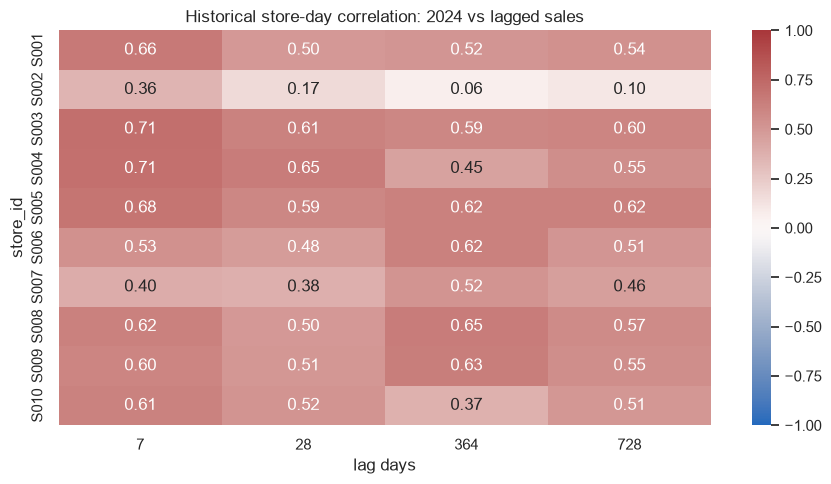

In [2]:
def lag_diagnostics(frame,group_cols,lags=(7,28,364,728)):
    rows=[]
    for lag in lags:
        prior=frame[['date']+group_cols+['sales_amount']].copy();prior['date']=prior.date+pd.Timedelta(days=lag);prior=prior.rename(columns={'sales_amount':'lagged_sales'})
        joined=frame.merge(prior,on=['date']+group_cols,how='inner',validate='one_to_one')
        joined['target_year']=joined.date.dt.year
        for key,g in joined.groupby(group_cols+['target_year'],observed=True):
            row=dict(zip(group_cols+['target_year'],key if isinstance(key,tuple) else (key,)))
            row.update(lag_days=lag,n=len(g),correlation=g.sales_amount.corr(g.lagged_sales) if len(g)>=30 and g.sales_amount.std()>0 and g.lagged_sales.std()>0 else np.nan,mean_difference=(g.sales_amount-g.lagged_sales).mean(),rmse=np.sqrt(np.mean((g.sales_amount-g.lagged_sales)**2)))
            rows.append(row)
    return pd.DataFrame(rows)
store_lags=lag_diagnostics(daily,['store_id'])
display(store_lags[store_lags.target_year.eq(2024)].pivot(index='store_id',columns='lag_days',values='correlation'))
display(store_lags[store_lags.target_year.eq(2024)].pivot(index='store_id',columns='lag_days',values='mean_difference'))
fig,ax=plt.subplots(figsize=(9,5));sns.heatmap(store_lags[store_lags.target_year.eq(2024)].pivot(index='store_id',columns='lag_days',values='correlation').astype(float),vmin=-1,vmax=1,center=0,cmap='vlag',annot=True,fmt='.2f',ax=ax);ax.set(title='Historical store-day correlation: 2024 vs lagged sales',xlabel='lag days');plt.tight_layout();plt.show()

## カテゴリごとの反復性
店舗×カテゴリ別の相関を、店舗単位の中央値・範囲で表示する。期間限定商品の販売期間や構成の変化に注意する。

stores  ...  max_correlation
category  lag_days          ...                 
dessert   7             10  ...           0.5847
          28            10  ...           0.5205
          364           10  ...           0.5848
          728           10  ...           0.5375
drink_bar 7             10  ...           0.7159
          28            10  ...           0.6602
          364           10  ...           0.6680
          728           10  ...           0.6736
kids      7             10  ...           0.7019
          28            10  ...           0.6658
          364           10  ...           0.7475
          728           10  ...           0.7109
lunch     7             10  ...           0.7384
          28            10  ...           0.6937
          364           10  ...           0.7884
          728           10  ...           0.7280
main      7             10  ...           0.6632
          28            10  ...           0.5970
          364           10  ...           0.5900
          728           10  ...           0.5517
side      7             10  ...           0.6195
          28            10  ...           0.4974
          364           10  ...           0.6151
          728           10  ...           0.5707

[24 rows x 4 columns]

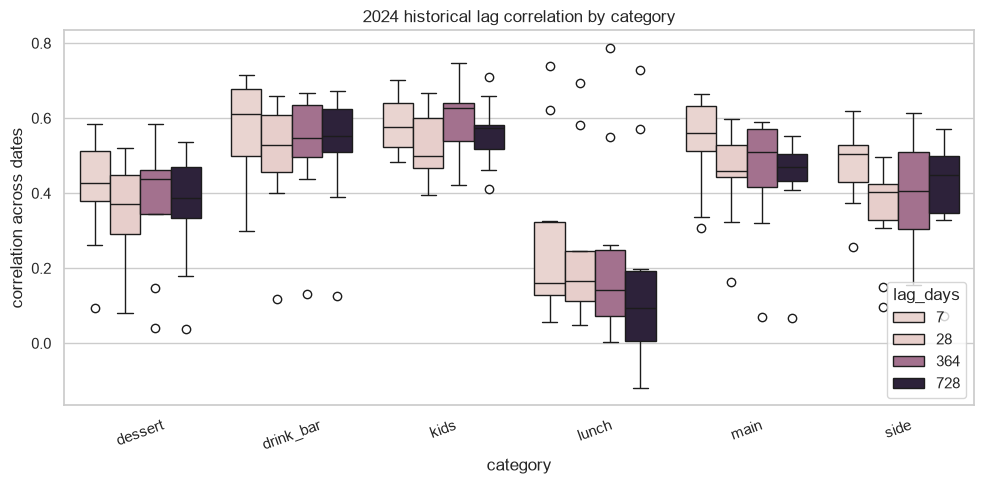

In [3]:
category_lags=lag_diagnostics(store_category,['store_id','category'])
c24=category_lags[category_lags.target_year.eq(2024)]
display(c24.groupby(['category','lag_days']).agg(stores=('correlation','count'),median_correlation=('correlation','median'),min_correlation=('correlation','min'),max_correlation=('correlation','max')))
fig,ax=plt.subplots(figsize=(10,5));sns.boxplot(data=c24,x='category',y='correlation',hue='lag_days',ax=ax);ax.set(title='2024 historical lag correlation by category',ylabel='correlation across dates');ax.tick_params(axis='x',rotation=20);plt.tight_layout();plt.show()

## 基準日時点で実績を参照できる予測日数
2023年末→2024年（閏年）と2024年末→2025年で比較する。予測対象日の `lag_days` 日前が基準日以前なら、そのラグ日は全て訓練期間に含まれるという前提。個々のデータに欠損がないかは別途確認する。

In [4]:
lags=[7,28,91,364,365,366,371,728]
rows=[]
for year in [2024,2025]:
    dates=pd.date_range(f'{year}-01-01',f'{year}-12-31');cutoff=pd.Timestamp(f'{year-1}-12-31')
    for lag in lags:
        lag_dates=dates-pd.Timedelta(days=lag)
        valid=(lag_dates<=cutoff)&(lag_dates>=daily.date.min())
        rows.append({'forecast_year':year,'cutoff':cutoff,'lag_days':lag,'target_days':len(dates),'available_days':int(valid.sum()),'unavailable_days':int((~valid).sum()),'available_fraction':float(valid.mean())})
availability=pd.DataFrame(rows)
display(availability)
display(availability.pivot(index='lag_days',columns='forecast_year',values='available_days'))
print('対象期間は2022-01-01以降の既存履歴のみとし、基準日の後と履歴開始前を未使用扱いにした。')

対象期間は2022-01-01以降の既存履歴のみとし、基準日の後と履歴開始前を未使用扱いにした。


,forecast_year,cutoff,lag_days,target_days,available_days,unavailable_days,available_fraction
0,2024,2023-12-31,7,366,7,359,0.0191
1,2024,2023-12-31,28,366,28,338,0.0765
2,2024,2023-12-31,91,366,91,275,0.2486
3,2024,2023-12-31,364,366,364,2,0.9945
4,2024,2023-12-31,365,366,365,1,0.9973
5,2024,2023-12-31,366,366,366,0,1.0000
6,2024,2023-12-31,371,366,366,0,1.0000
7,2024,2023-12-31,728,366,366,0,1.0000
8,2025,2024-12-31,7,365,7,358,0.0192
9,2025,2024-12-31,28,365,28,337,0.0767


forecast_year,2024,2025
lag_days,,
7,7,7
28,28,28
91,91,91
364,364,364
365,365,365
366,366,365
371,366,365
728,366,365


## 具体例：2025年末までのラグ日
2025年の実績はない。指定した予測日に対するラグ日が2024年末以前なら履歴として参照できる。

In [5]:
cutoff=pd.Timestamp('2024-12-31')
examples=pd.to_datetime(['2025-01-01','2025-01-07','2025-02-01','2025-06-30','2025-12-30','2025-12-31'])
example_rows=[]
for date in examples:
    for lag in [7,28,364,365,371,728]:
        lag_date=date-pd.Timedelta(days=lag)
        example_rows.append({'forecast_date':date,'lag_days':lag,'lag_date':lag_date,'available':bool(daily.date.min()<=lag_date<=cutoff),'same_weekday':date.dayofweek==lag_date.dayofweek})
examples_df=pd.DataFrame(example_rows)
display(examples_df)
print('364日・371日は曜日が揃う。364日ラグには予測期間末で基準日後になる日があるが、371日ラグは両年の全日で基準日以前となる。')

364日・371日は曜日が揃う。364日ラグには予測期間末で基準日後になる日があるが、371日ラグは両年の全日で基準日以前となる。


,forecast_date,lag_days,lag_date,available,same_weekday
0,2025-01-01,7,2024-12-25,True,True
1,2025-01-01,28,2024-12-04,True,True
2,2025-01-01,364,2024-01-03,True,True
3,2025-01-01,365,2024-01-02,True,False
4,2025-01-01,371,2023-12-27,True,True
5,2025-01-01,728,2023-01-04,True,True
6,2025-01-07,7,2024-12-31,True,True
7,2025-01-07,28,2024-12-10,True,True
8,2025-01-07,364,2024-01-09,True,True
9,2025-01-07,365,2024-01-08,True,False


## 解釈と設計上の注意
- 日次ラグ相関は2024年の過去データを含む記述統計。2024年や2025年の通年予測へ、そのまま同年の未観測実績を投入してはいけない。
- 短期ラグを使う場合は、予測された値を再帰利用する設計、事前集計された同曜日の過去統計、または長いラグ等を検討する。どの場合も2024年末時点で実現可能か検証する。
- 2024年は366日、2025年は365日。日付・曜日・月・祝日が単純な前年コピーで一致するとは限らない。
- 天候観測や来店・注文の同日値は、将来ラグとして見かけ上参照できても、予測基準日後の値は使えない。